Name Haoxin Ni

Labpartner(s)

In [9]:
# Imports for W.1
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# Class 8.2

Today we are having a guest lecture online by [Will Faulkner](https://www.linkedin.com/in/wnfaulkner/) on "vibe coding" aka the use of LLMs to build code when you have no or little idea what you are doing. 

**W.1** This week our warmups are focused on applying your Pandas skills. Please continue your analysis of the 2026 World Cup player stats from slack (pinned to #announcements). Make sure you write some text about what you found. 

### W.1: Total goals versus goals per 90 minutes

This continues the Lab 8.1 analysis of `player_stats.csv`.
Lab 8.1 compared total goals, playing time, and position-level scoring rates.
Here I compare **individual scoring rates** and investigate how the minimum
playing-time requirement changes the ranking.

I calculate **goals per 90 minutes = 90 × goals / minutes played**. Players with
zero minutes are excluded from this calculation. For the main comparison,
I require **at least 180 minutes**, the equivalent of two full 90-minute games.
This is an exploratory cutoff, so I also check 90 and 270 minutes. Team labels
remain numerical IDs because the supplied CSV has no country-name lookup.

In [10]:
# Read the same dataset used in Lab 8.1.
data_path = Path('player_stats.csv')
if not data_path.exists():
    data_path = Path('week8/player_stats.csv')
players = pd.read_csv(data_path)

# Check the fields used in this analysis before calculating rates.
required = ['player_id', 'player_name', 'team_id', 'position',
            'minutes_played', 'goals', 'assists']
print(f'Players in the file: {len(players):,}')
print(f'Duplicate player IDs: {players["player_id"].duplicated().sum()}')
print('Missing values in the analysis columns:')
display(players[required].isna().sum().rename('missing_values').to_frame())

# Keep positive minutes so no individual rate divides by zero.
active = players.loc[players['minutes_played'] > 0, required].copy()
active['goals_per_90'] = 90 * active['goals'] / active['minutes_played']
print(f'Players with positive minutes: {len(active):,}')
print(f'Players excluded for zero minutes: {(players["minutes_played"] == 0).sum()}')

# Inspect the leading rate before applying a playing-time cutoff.
unfiltered_top = active.sort_values(
    ['goals_per_90', 'goals', 'minutes_played', 'player_id'],
    ascending=[False, False, False, True]
).head(3)
display(unfiltered_top[
    ['player_name', 'minutes_played', 'goals', 'goals_per_90']
].round(3).reset_index(drop=True))

Players in the file: 1,248
Duplicate player IDs: 0
Missing values in the analysis columns:


,missing_values
player_id,0
player_name,0
team_id,0
position,0
minutes_played,0
goals,0
assists,0


Players with positive minutes: 1,039
Players excluded for zero minutes: 209


,player_name,minutes_played,goals,goals_per_90
0,Kaan Ayhan,2,1,45.000
1,Mattias Olof Svanberg,14,1,6.429
2,Jaminton Leandro Campaz,21,1,4.286


### Compare the two rankings using the same eligible players

In [11]:
minimum_minutes = 180
eligible = active.loc[active['minutes_played'] >= minimum_minutes].copy()
columns = ['player_name', 'team_id', 'position', 'minutes_played',
           'goals', 'assists', 'goals_per_90']

top_totals = eligible.sort_values(
    ['goals', 'assists', 'minutes_played', 'player_id'],
    ascending=[False, False, False, True]
).head(10)
top_rates = eligible.sort_values(
    ['goals_per_90', 'goals', 'minutes_played', 'player_id'],
    ascending=[False, False, False, True]
).head(10)

print(f'Eligible players with at least {minimum_minutes} minutes: {len(eligible)}')
print('Top 10 by total goals:')
display(top_totals[columns].round(3).reset_index(drop=True))
print('Top 10 by goals per 90 minutes:')
display(top_rates[columns].round(3).reset_index(drop=True))

Eligible players with at least 180 minutes: 560
Top 10 by total goals:


,player_name,team_id,position,minutes_played,goals,assists,goals_per_90
0,Kylian Mbappe,33,FWD,711,10,4,1.266
1,Lionel Andrés Messi,37,FWD,590,8,4,1.220
2,Jude Victor William Bellingham,45,MID,596,7,1,1.057
3,Erling Braut Haaland,36,FWD,450,7,0,1.400
4,Harry Edward Kane,45,FWD,534,6,1,1.011
5,Masour Ousmane Dembele,33,FWD,363,5,2,1.240
6,Mikel Oyarzabal,29,FWD,394,5,1,1.142
7,José Vinicius,9,FWD,441,4,1,0.816
8,Ismaila Sarr,34,FWD,366,4,1,0.984
9,Bradley Jean-Manuel Essolisa Barcola,33,FWD,283,4,1,1.272


Top 10 by goals per 90 minutes:


,player_name,team_id,position,minutes_played,goals,assists,goals_per_90
0,Julián Andrés Quinones,1,FWD,221,4,1,1.629
1,Erling Braut Haaland,36,FWD,450,7,0,1.400
2,Raúl Alonso Jimenez,1,FWD,193,3,0,1.399
3,Romelu Lukaku,25,FWD,206,3,0,1.311
4,Bradley Jean-Manuel Essolisa Barcola,33,FWD,283,4,1,1.272
5,Kylian Mbappe,33,FWD,711,10,4,1.266
6,Masour Ousmane Dembele,33,FWD,363,5,2,1.240
7,Lionel Andrés Messi,37,FWD,590,8,4,1.220
8,Brian Ebenezer Adjei Brobbey,21,FWD,225,3,0,1.200
9,Mikel Oyarzabal,29,FWD,394,5,1,1.142


In [12]:
# Show how the leading rate changes when the cutoff changes.
# Use all eligible players, including those with zero goals, for the count.
cutoff_results = []
for cutoff in [90, 180, 270]:
    candidates = active.loc[active['minutes_played'] >= cutoff]
    ranked = candidates.sort_values(
        ['goals_per_90', 'goals', 'minutes_played', 'player_id'],
        ascending=[False, False, False, True]
    )
    leader = ranked.iloc[0]
    cutoff_results.append({
        'minimum_minutes': cutoff,
        'eligible_players': len(candidates),
        'leading_player': leader['player_name'],
        'leader_minutes': leader['minutes_played'],
        'leader_goals': leader['goals'],
        'leader_goals_per_90': leader['goals_per_90']
    })

cutoff_summary = pd.DataFrame(cutoff_results)
display(cutoff_summary.round(3))

,minimum_minutes,eligible_players,leading_player,leader_minutes,leader_goals,leader_goals_per_90
0,90,767,Soufiane Rahimi,91,2,1.978
1,180,560,Julián Andrés Quinones,221,4,1.629
2,270,355,Erling Braut Haaland,450,7,1.400


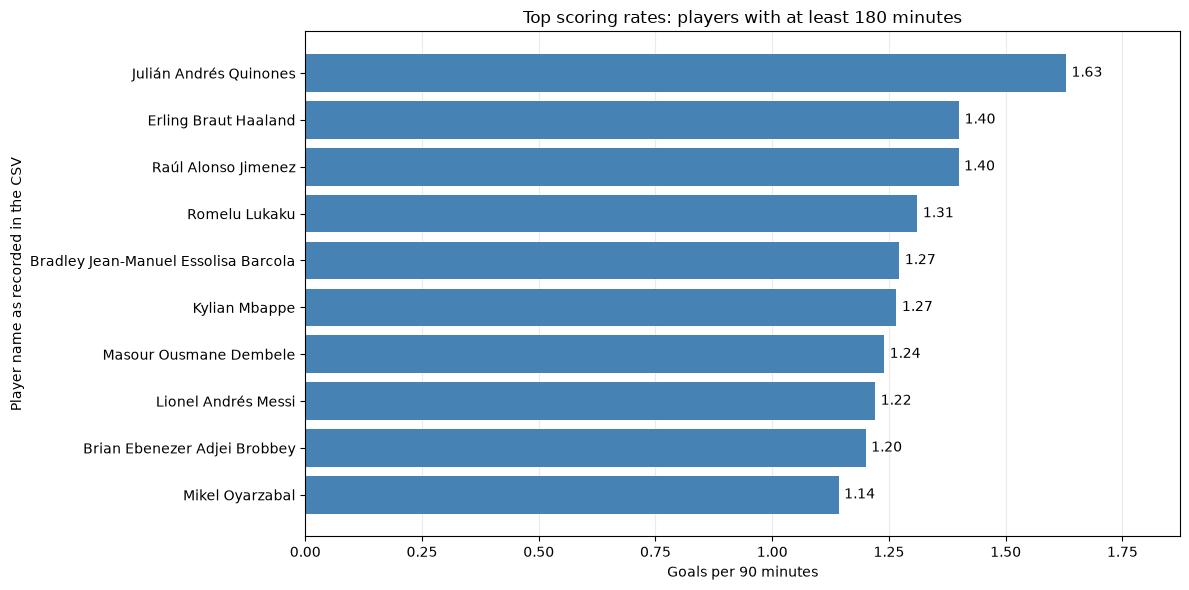

In [13]:
# Plot the ten highest rates with the 180-minute cutoff.
plot_data = top_rates.sort_values('goals_per_90')
fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(plot_data['player_name'], plot_data['goals_per_90'],
               color='steelblue')
ax.bar_label(bars, fmt='%.2f', padding=4)
ax.set_title(f'Top scoring rates: players with at least {minimum_minutes} minutes')
ax.set_xlabel('Goals per 90 minutes')
ax.set_ylabel('Player name as recorded in the CSV')
ax.set_xlim(0, plot_data['goals_per_90'].max() * 1.15)
ax.set_axisbelow(True)
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
plt.show()

### What I found

There are **1,039 players with positive recorded minutes**. The analysis columns
have no missing values, and player IDs are unique. Without a playing-time
cutoff, **Kaan Ayhan** leads with **45.000 goals per 90 minutes**, based on
**1 goal in only 2 recorded minutes**. This illustrates how a very small
denominator can produce an extreme rate. The number describes this CSV entry
and should not be interpreted as a dependable future scoring rate.

With the **180-minute cutoff**, **560 players** qualify. **Kylian Mbappe** leads
in total goals with **10 in 711 minutes**, equivalent to **1.266 goals per 90
minutes**. However, **Julián Andrés Quinones** leads the rate ranking with
**4 goals in 221 minutes**, or **1.629 per 90**. **Erling Braut Haaland** follows
with **7 goals in 450 minutes**, or **1.400 per 90**. Total goals and goals per
90 therefore produce different leaders even when applied to the same players.

The sensitivity check shows that the cutoff matters. At **90 minutes**, there
are **767 eligible players**, and **Soufiane Rahimi** leads with **1.978 goals
per 90** from 2 goals in 91 minutes. At **270 minutes**, only **355 players**
qualify, and **Haaland** leads with **1.400 per 90**. Quinones no longer qualifies
because his recorded playing time is 221 minutes. A ranking should therefore
state its playing-time requirement alongside its results.

Goals per 90 helps compare scoring output for different amounts of playing
time, but it does not account for opponents, position, penalties, or match
circumstances. The 180-minute cutoff removes very short appearances but still
leaves uncertainty from a small number of goals. These findings describe the
supplied dataset; unusual names and records are retained as provided. Because
`shots` and `shots_on_target` are entirely missing, this file cannot support a
shot-conversion analysis.

# Lecture 8.2

### Agenda: Will will talk about vibe coding, we'll have a break, and then he'll share some examples


### Questions

# Lab 8.2

**E.0** Complete the previous labs if you are behind.

**E.1** "Vibe coding" in practice, part 1. Take a dataset of your choice and use an LLM to do some kind of manipulation or analysis of that data. You should focus on trying something that you couldn't easily figure out on your own. Paste the resulting code and results here.

### E.1: Unsupervised clustering of storm-track shapes

**Question:** which storms have similar path geometry after removing their
starting location, total path length, and travel speed? I used the previously
downloaded [NOAA IBTrACS archive](https://www.ncei.noaa.gov/products/international-best-track-archive),
but selected **2020 North Atlantic storms**. This is an exploratory geometry
exercise, separate from the final project's 2021 TempestExtremes validation.
The accompanying NetCDF contains 30 named main tracks from that season.

**AI task:** build an explainable pipeline for geodesic preprocessing,
constrained dynamic time warping (DTW), and hierarchical clustering. Codex
helped write, explain, and check the implementation. The main choices are:

1. Keep each storm's longest contiguous tropical-system (`nature == 'TS'`)
   segment, splitting at gaps over 12 hours. Require at least 72 hours and
   500 km of travel. In IBTrACS, `TS` here means tropical system, not an
   intensity category.
2. Use WGS84 geodesic distances and bearings to express positions relative
   to the first point. Divide coordinates by total geodesic path length and
   interpolate 40 points at equal fractions of cumulative travel distance.
   North/east orientation is retained; the curves are not rotated.
3. Compare the two-dimensional curves with constrained DTW. The baseline
   allows alignment within 8 of 40 progress indices. This aligns **path
   progress**, not clock time. The score is the square root of accumulated
   squared coordinate error divided by `sqrt(n + m)`.
4. Apply average-linkage clustering to the distance matrix. Compare 2–5 groups
   using silhouette scores and choose an actual member as each group's medoid
   (minimum summed distance to the other members).

Method references: [pyproj geodesics](https://pyproj4.github.io/pyproj/stable/api/geod.html),
[DTW](https://dtaidistance.readthedocs.io/en/latest/modules/dtw.html),
[SciPy linkage](https://docs.scipy.org/doc/scipy/reference/generated/scipy.cluster.hierarchy.linkage.html),
and [silhouette definition](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.silhouette_score.html).
The short DTW and silhouette functions below implement the stated formulas.

In [14]:
import numpy as np
import xarray as xr
from pyproj import Geod
from scipy.cluster.hierarchy import linkage, cut_tree, dendrogram
from scipy.spatial.distance import squareform

lab_folder = Path('.') if Path('lab82_resources').is_dir() else Path('week8')
geod = Geod(ellps='WGS84')
N_POINTS = 40
BAND = 8
selected = []
excluded = []

with xr.open_dataset(lab_folder / 'lab82_resources/IBTrACS_NA_2020_tracks.nc') as data:
    for i in range(data.sizes['storm']):
        storm = data.isel(storm=i)
        name = storm['name'].item().decode().strip()
        frame = pd.DataFrame({
            'time': pd.to_datetime(storm['time'].values, utc=True).round('s'),
            'lon': storm['lon'].values, 'lat': storm['lat'].values,
            'nature': storm['nature'].values.astype(str)
        })
        frame = frame.loc[frame['nature'].eq('TS')].dropna(
            subset=['time', 'lon', 'lat']).sort_values('time')
        assert frame['time'].is_unique
        if frame.empty:
            excluded.append({'storm': name, 'reason': 'no tropical-system segment'})
            continue

        # Do not join disconnected tropical phases across long gaps.
        blocks = (frame['time'].diff() > pd.Timedelta(hours=12)).cumsum()
        spans = frame.groupby(blocks)['time'].agg(
            lambda times: (times.max() - times.min()).total_seconds())
        frame = frame.loc[blocks.eq(spans.idxmax())]
        hours = (frame['time'].iloc[-1] - frame['time'].iloc[0]).total_seconds() / 3600
        if hours < 72:
            excluded.append({'storm': name, 'reason': 'segment shorter than 72 h'})
            continue

        lon, lat = frame['lon'].to_numpy(), frame['lat'].to_numpy()
        _, _, steps = geod.inv(lon[:-1], lat[:-1], lon[1:], lat[1:])
        cumulative = np.r_[0, np.cumsum(steps)]
        total_m = cumulative[-1]
        if total_m < 500_000:
            excluded.append({'storm': name, 'reason': 'path shorter than 500 km'})
            continue

        # Origin-centered azimuthal coordinates: east = d*sin(bearing), north = d*cos(bearing).
        bearing, _, radial = geod.inv(np.full(len(lon), lon[0]),
                                     np.full(len(lat), lat[0]), lon, lat)
        angle = np.deg2rad(bearing)
        xy = np.column_stack([radial * np.sin(angle), radial * np.cos(angle)]) / total_m
        keep = np.r_[True, np.diff(cumulative) > 0]  # remove repeated-distance knots
        progress = cumulative[keep] / total_m
        curve = np.column_stack([
            np.interp(np.linspace(0, 1, N_POINTS), progress, xy[keep, axis])
            for axis in [0, 1]
        ])
        selected.append({'storm': name, 'sid': storm['sid'].item().decode(),
                         'segment_hours': hours, 'path_km': total_m / 1000,
                         'curve': curve})

names = [item['storm'] for item in selected]
shapes = np.stack([item['curve'] for item in selected])
track_info = pd.DataFrame([{key: value for key, value in item.items() if key != 'curve'}
                           for item in selected])
print(f'Kept {len(selected)} of {len(selected) + len(excluded)} candidate storms.')
display(pd.DataFrame(excluded))

Kept 22 of 30 candidate storms.


,storm,reason
0,ARTHUR,segment shorter than 72 h
1,BERTHA,segment shorter than 72 h
2,DOLLY,segment shorter than 72 h
3,EDOUARD,segment shorter than 72 h
4,FAY,segment shorter than 72 h
5,KYLE,segment shorter than 72 h
6,NANA,segment shorter than 72 h
7,ALPHA,no tropical-system segment


In [15]:
def shape_dtw(a, b, band=BAND):
    """Constrained DTW: square-root accumulated squared cost / sqrt(n + m)."""
    n, m = len(a), len(b)
    cost = np.full((n + 1, m + 1), np.inf)
    cost[0, 0] = 0
    for i in range(1, n + 1):
        for j in range(max(1, i - band), min(m, i + band) + 1):
            local_cost = np.sum((a[i - 1] - b[j - 1]) ** 2)
            cost[i, j] = local_cost + min(cost[i - 1, j], cost[i, j - 1], cost[i - 1, j - 1])
    return np.sqrt(cost[n, m] / (n + m))


def distance_matrix(curves, band):
    matrix = np.zeros((len(curves), len(curves)))
    for i in range(len(curves)):
        for j in range(i):
            matrix[i, j] = matrix[j, i] = shape_dtw(curves[i], curves[j], band)
    return matrix


def mean_silhouette(matrix, labels):
    """Mean (b - a) / max(a, b), with singleton silhouettes set to zero."""
    scores = []
    for i, label in enumerate(labels):
        own = np.flatnonzero(labels == label)
        if len(own) == 1:
            scores.append(0.0)
            continue
        a = matrix[i, own[own != i]].mean()
        b = min(matrix[i, labels == other].mean()
                for other in np.unique(labels) if other != label)
        scores.append((b - a) / max(a, b) if max(a, b) > 0 else 0.0)
    return float(np.mean(scores))


D = distance_matrix(shapes, BAND)
# squareform gives SciPy pairwise distances, rather than treating rows as features.
# Average linkage can use these dissimilarities; Ward would require Euclidean geometry.
tree = linkage(squareform(D), method='average', optimal_ordering=True)
candidates = []
for k in [2, 3, 4, 5]:
    trial_labels = cut_tree(tree, n_clusters=k).ravel() + 1
    candidates.append({'clusters': k, 'silhouette': mean_silhouette(D, trial_labels)})
k_scores = pd.DataFrame(candidates)
best_k = int(k_scores.loc[k_scores['silhouette'].idxmax(), 'clusters'])
labels = cut_tree(tree, n_clusters=best_k).ravel() + 1
track_info['cluster'] = labels

medoids = {}
cluster_rows = []
for group in np.unique(labels):
    members = np.flatnonzero(labels == group)
    medoid = members[np.argmin(D[np.ix_(members, members)].sum(axis=1))]
    medoids[int(group)] = int(medoid)
    cluster_rows.append({'cluster': group, 'storms': len(members), 'medoid': names[medoid]})

display(k_scores.round(3))
display(pd.DataFrame(cluster_rows))
display(track_info.sort_values(['cluster', 'storm']).round({'path_km': 1}))
upper = np.triu_indices(len(names), 1)
closest = np.argmin(D[upper])
pair_i, pair_j = upper[0][closest], upper[1][closest]
print(f'Closest pair: {names[pair_i]} and {names[pair_j]}, DTW score = {D[pair_i, pair_j]:.4f}')

,clusters,silhouette
0,2,0.562
1,3,0.508
2,4,0.464
3,5,0.441


,cluster,storms,medoid
0,1,20,SALLY
1,2,2,OMAR


,storm,sid,segment_hours,path_km,cluster
14,BETA,2020261N21265,129.0,1286.2,1
0,CRISTOBAL,2020154N19269,195.0,3234.4,1
16,DELTA,2020279N16284,141.0,3051.5,1
17,EPSILON,2020291N32305,165.0,4118.7,1
19,ETA,2020306N15288,171.0,3641.0,1
15,GAMMA,2020276N17277,102.0,1160.2,1
1,GONZALO,2020203N09323,96.0,2438.4,1
2,HANNA,2020205N26272,90.0,1262.8,1
21,IOTA,2020318N16289,120.0,1765.0,1
3,ISAIAS,2020211N13306,141.0,3776.2,1


Closest pair: JOSEPHINE and WILFRED, DTW score = 0.0236


In [16]:
# Keep the selected number of groups fixed and change the allowed warping.
# Agreement compares every pair's same-cluster/different-cluster status.
base_pairs = (labels[:, None] == labels[None, :])[upper]
sensitivity = []
for band in [4, 8, 12]:
    alternate_D = D if band == BAND else distance_matrix(shapes, band)
    alternate_tree = linkage(squareform(alternate_D), method='average', optimal_ordering=True)
    alternate_labels = cut_tree(alternate_tree, n_clusters=best_k).ravel() + 1
    alternate_pairs = (alternate_labels[:, None] == alternate_labels[None, :])[upper]
    sensitivity.append({'band_points': band,
                        'pair_assignment_agreement': np.mean(base_pairs == alternate_pairs),
                        'silhouette': mean_silhouette(alternate_D, alternate_labels)})
display(pd.DataFrame(sensitivity).round(3))

,band_points,pair_assignment_agreement,silhouette
0,4,1.0,0.563
1,8,1.0,0.562
2,12,1.0,0.562


### Results

The filters retain **22 of 30 storms**. Of the group counts tested, **two groups**
have the highest mean silhouette (**0.562**). One contains **20 storms** with
Sally as its medoid. The other contains **Omar and Theta**, with Omar selected
as medoid; either member has the same summed distance in a two-storm group.
**Josephine and Wilfred** are the closest pair overall, with a score of
**0.0236**. These are dimensionless shape dissimilarities, not position errors
in kilometres.

With the number of groups fixed at two, bands of 4, 8, and 12 points give the
same pair assignments. This checks one parameter only. The large 20-member
group is still heterogeneous, and the silhouette was selected on this same
small sample. Duration filters, projection, resampling, and normalization can
change the result. These groups are exploratory, not established storm types
or evidence of distinct physical mechanisms.

**E.2** "Vibe coding" in practice, part 2. Now take the same data set and make some kind of plot, again focusing on something that would be difficult to figure out on your own. Paste the resulting code and results here.

### E.2: Visualizing the hierarchy and representative shapes

The first figure combines a dendrogram with the pairwise DTW heatmap in the
same storm order. The second overlays every normalized curve within its group,
with the medoid in black. A circle marks the common origin and a triangle marks
the medoid's endpoint. These are shape diagrams, not geographic maps.

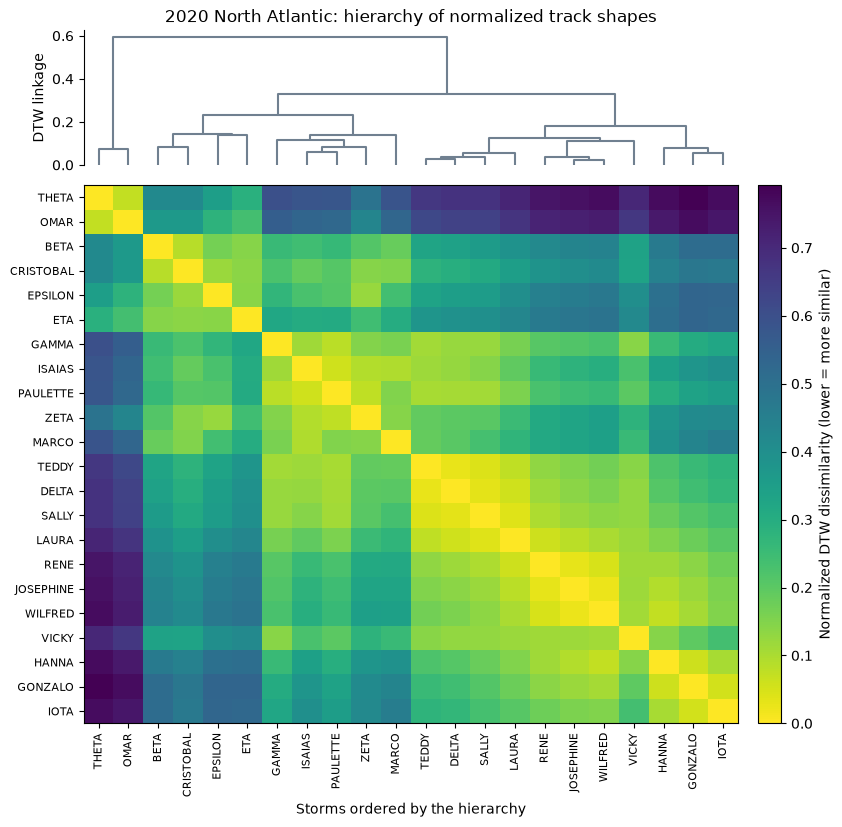

In [17]:
# Link the hierarchical tree and reordered distance matrix in one figure.
fig = plt.figure(figsize=(9, 9))
grid = fig.add_gridspec(2, 2, height_ratios=[1, 4], width_ratios=[1, 0.035],
                       hspace=0.06, wspace=0.06)
ax_tree = fig.add_subplot(grid[0, 0])
branches = dendrogram(tree, ax=ax_tree, no_labels=True,
                      color_threshold=0, above_threshold_color='slategray')
order = branches['leaves']
ax_tree.set_title('2020 North Atlantic: hierarchy of normalized track shapes')
ax_tree.set_ylabel('DTW linkage')
ax_tree.set_xticks([])
ax_tree.spines[['top', 'right', 'bottom']].set_visible(False)

ax_heat = fig.add_subplot(grid[1, 0])
n = len(names)
image = ax_heat.imshow(D[np.ix_(order, order)], cmap='viridis_r', origin='upper',
                       extent=(0, 10*n, 10*n, 0), interpolation='nearest', aspect='auto')
positions = 5 + 10 * np.arange(n)
ax_heat.set_xticks(positions, [names[i] for i in order], rotation=90, fontsize=8)
ax_heat.set_yticks(positions, [names[i] for i in order], fontsize=8)
ax_heat.set_xlabel('Storms ordered by the hierarchy')
color_axis = fig.add_subplot(grid[1, 1])
fig.colorbar(image, cax=color_axis, label='Normalized DTW dissimilarity (lower = more similar)')
plt.show()

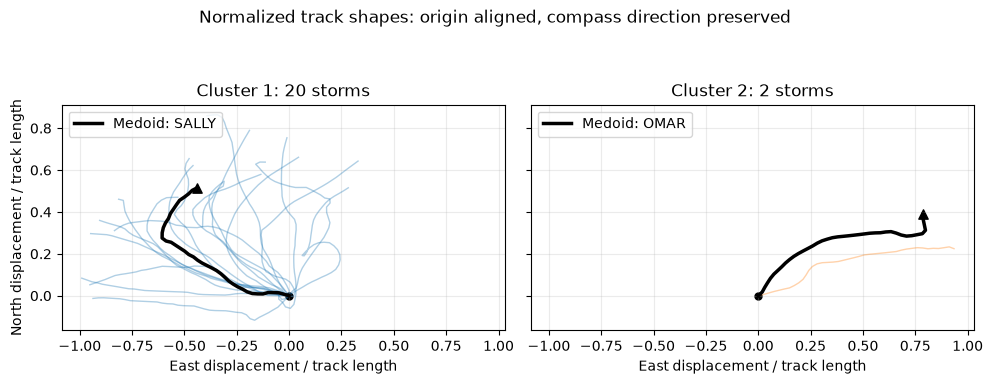

In [18]:
# Overlay each group's normalized curves; the medoid is an actual member.
fig, axes = plt.subplots(1, best_k, figsize=(5 * best_k, 3.8),
                         sharex=True, sharey=True, squeeze=False)
cluster_colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
for group, ax in zip(sorted(medoids), axes.ravel()):
    members = np.flatnonzero(labels == group)
    for i in members:
        ax.plot(shapes[i, :, 0], shapes[i, :, 1],
                color=cluster_colors[group - 1], alpha=0.35, linewidth=1)
    representative = medoids[group]
    curve = shapes[representative]
    ax.plot(curve[:, 0], curve[:, 1], color='black', linewidth=2.5,
            label=f'Medoid: {names[representative]}')
    ax.scatter(0, 0, color='black', marker='o', s=25)
    ax.scatter(curve[-1, 0], curve[-1, 1], color='black', marker='^', s=45)
    ax.set_title(f'Cluster {group}: {len(members)} storms')
    ax.set_xlabel('East displacement / track length')
    ax.set_aspect('equal', adjustable='box')
    ax.grid(alpha=0.25)
    ax.legend(loc='upper left')
axes[0, 0].set_ylabel('North displacement / track length')
fig.suptitle('Normalized track shapes: origin aligned, compass direction preserved')
fig.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

Omar and Theta form the small group with mainly eastward displacement. The
larger group mostly moves westward and/or northward, with a wide range of
turning shapes. The medoid is a representative member, not a mean trajectory.
Starting location, absolute length, and speed were intentionally removed, so
this plot cannot describe landfall risk, intensity, or storm damage.

**E.3** Now let's think, does your use of AI in the examples above fit into Wiley's best practices framework? What are the dangers and oppertunities here? Use specific examples from the Wiley resources and relate them to your workflow above:

https://www.wiley.com/en-us/publishing/book/ai-guidelines

https://www.wiley.com/en-us/publishing/article/ai-guidelines

Specifically, when is it ethical to use AI for research, and when is it not? When is it in your best interest as a student to use AI, and when is it not? What are the enviornmental considerations of using AI? How might you use AI in your final project in line with ethical guidelines? You should be writng a few paragraphs at minimum with examples here. 


### E.3: A short reflection on AI use

Vibe coding helped implement DTW and geodesic preprocessing beyond the Pandas
basics from Lab 8.1. Wiley's [book guidance](https://www.wiley.com/en-us/publishing/book/ai-guidelines)
emphasizes human oversight and documenting AI contributions. Codex generated
code and draft explanations here. Checks cover distances, the DTW recurrence,
and clustering inputs, but I still need to understand and review the analysis.

Wiley's [research guidance](https://www.wiley.com/en-us/publishing/article/ai-guidelines)
requires transparency and researcher accountability. AI is useful for debugging
and exploring methods; inventing data or presenting unverified clusters as
scientific discoveries would be unethical. For example, ordinary Ward linkage
would be inappropriate for this DTW matrix. The analysis uses average linkage
and identifies the groups as exploratory. Confidential data would also require
checking privacy protections before using an AI tool.

As a student, I benefit when I connect the generated code to familiar filtering,
indexing, and plotting, then learn why the unfamiliar steps are needed. Copying
code I cannot explain would undermine that learning. In my final project I
would disclose AI help, preserve the source data, and independently check the
methods and claims rather than adopting the generated conclusions unchanged.

Wiley's [environmental discussion](https://www.wiley.com/en-kr/publish/article/ai-guidelines/)
notes the energy cost of repeated queries and complex AI workflows. I can
reuse the small local subset and deterministic code, and avoid new AI calls
for routine reruns. The cluster analysis itself runs locally without training
a generative model.

**E.4** Make notes for yourself on progamming tecniques and commands you learned in the this week, including examples, comments and explainitory text. You can do this here or in a separate notebook that you link to here. Basically, you are making a cheat sheet for yourself.

### E.4: This week's programming notes

- **Vibe coding:** specify the scientific question, data fields, and assumptions.
  Ask for explanations and checks, then inspect the results before interpreting them.
- **Pandas from Lab 8.1:** `dropna()`, `sort_values()`, and `groupby()` help remove
  padding and select contiguous storm segments.
- **`Geod.inv()`** returns bearings and distances on an ellipsoid. Longitude
  and latitude differences alone are not distances in kilometres.
- **`np.interp()`** creates comparable positions along a curve. Interpolated
  points are not new observations.
- **DTW:** dynamic programming compares sequence shapes while allowing limited
  alignment shifts. The band controls how much distortion is permitted.
- **`squareform()` + `linkage(method='average')`** cluster the supplied distances.
  Feeding the square matrix directly to `linkage()` would instead treat rows
  as feature vectors.
- **Medoid and sensitivity:** choose a real representative and check whether
  reasonable parameter changes alter the assignments. A clear plot does not
  establish a physical explanation.

Example: identify each storm's nearest neighbour from the computed matrix.

In [19]:
# Exclude self-distance before selecting nearest neighbours.
other_distances = D.copy()
np.fill_diagonal(other_distances, np.inf)
nearest = other_distances.argmin(axis=1)
neighbours = pd.DataFrame({
    'storm': names,
    'nearest_storm': [names[j] for j in nearest],
    'DTW_score': D[np.arange(len(names)), nearest]
})
display(neighbours.sort_values('DTW_score').head(8).round(4))

,storm,nearest_storm,DTW_score
13,WILFRED,JOSEPHINE,0.0236
4,JOSEPHINE,WILFRED,0.0236
10,TEDDY,DELTA,0.0254
16,DELTA,TEDDY,0.0254
8,RENE,JOSEPHINE,0.0304
11,SALLY,DELTA,0.0320
5,LAURA,SALLY,0.0379
21,IOTA,GONZALO,0.0538
